# TITANIC
## Patterns, probabilities, and the limits of hindsight

**Question:** What descriptive survival patterns occur in this selected historical sample, and how well do prespecified models predict survival on a genuinely held-out subset?

This is a historical observational case study, not a rescue-prioritization system. No individual simulation or causal claim is offered.

### Decision log / public data, bounded scope

- Source: committed `data/passengers.csv`, a minimal extract of the pinned, CC0-declared `titanic` R-package source; see root provenance files.
- Coverage: **891 labeled records**, not the full ship manifest; no extra notebook sampling.
- Level: standard EDA plus association discovery and prespecified predictive analysis.
- Protocol: seed 20261014, committed ticket-grouped split and five training folds. 712 training records, 179 held out. No tuning on the test set.
- Original names, tickets and cabin strings are not loaded; group labels and IDs are never predictors.
- Every analytical computation below calls reusable code in `Python/`.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'data' / 'passengers.csv').exists():
    root = root.parent
sys.path.insert(0, str(root))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from Python.analysis import load_data, missingness, run_analysis, MODELS
from Python.figures import eda_figure
pd.set_option('display.max_columns', 20)
data = load_data(root)
print(f'{len(data):,} records | {data.PassengerId.nunique():,} unique passenger IDs')
display(data.drop(columns=['ticket_group']).head())
display(data.groupby('subset').Survived.agg(['size', 'sum', 'mean']))

891 records | 891 unique passenger IDs


,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,subset,cv_fold
0,1,0,3,male,22.0,1,0,7.2500,S,train,4
1,2,1,1,female,38.0,1,0,71.2833,C,train,2
2,3,1,3,female,26.0,0,0,7.9250,S,train,0
3,4,1,1,female,35.0,1,0,53.1000,S,train,2
4,5,0,3,male,35.0,0,0,8.0500,S,train,1


,size,sum,mean
subset,,,
test,179,69,0.385475
train,712,273,0.383427


## 01 / First understand what was recorded

Missing ages are retained as unknown in association baskets and imputed only within model-training partitions. Fare and age distributions are not symmetric. Missing records and the labeled-sample selection constrain interpretation; outliers are not automatically errors.

In [2]:
display(missingness(data))
print('Exact duplicate records:', data.duplicated().sum())
display(data[['Age', 'Fare', 'SibSp', 'Parch']].describe())
display(data[['Pclass', 'Age', 'Fare', 'SibSp', 'Parch', 'Survived']].corr(method='spearman'))
figure = eda_figure(data)
display(figure)
plt.close(figure)

,field,n_missing,pct_missing
0,PassengerId,0,0.000000
1,Survived,0,0.000000
2,Pclass,0,0.000000
3,Sex,0,0.000000
4,Age,177,0.198653
5,SibSp,0,0.000000
6,Parch,0,0.000000
7,Fare,0,0.000000
8,Embarked,2,0.002245


Exact duplicate records: 0


,Age,Fare,SibSp,Parch
count,714.000000,891.000000,891.000000,891.000000
mean,29.699118,32.204208,0.523008,0.381594
std,14.526497,49.693429,1.102743,0.806057
min,0.420000,0.000000,0.000000,0.000000
25%,20.125000,7.910400,0.000000,0.000000
50%,28.000000,14.454200,0.000000,0.000000
75%,38.000000,31.000000,1.000000,0.000000
max,80.000000,512.329200,8.000000,6.000000


,Pclass,Age,Fare,SibSp,Parch,Survived
Pclass,1.000000,-0.361666,-0.688032,-0.043019,-0.022801,-0.339668
Age,-0.361666,1.000000,0.135051,-0.182061,-0.254212,-0.052565
Fare,-0.688032,0.135051,1.000000,0.447113,0.410074,0.323736
SibSp,-0.043019,-0.182061,0.447113,1.000000,0.450014,0.088879
Parch,-0.022801,-0.254212,0.410074,0.450014,1.000000,0.138266
Survived,-0.339668,-0.052565,0.323736,0.088879,0.138266,1.000000


<Figure size 1200x800 with 4 Axes>

## 02 / Describe uncertainty before predicting

Within each sex-by-class group, start with Beta(1,1), add observed survived and non-survived counts, and calculate the exact central 95% beta credible interval. These summaries use **all 891 labeled records** and are separate from predictive evaluation. They describe this selected sample, not causal sex or class effects in a population.

In [3]:
data, tables, summary = run_analysis(root)
display(tables['bayesian_rates'])
print('Survived:', summary['survived'], 'of', summary['n'])

,sex,pclass,n,survived,observed_rate,posterior_mean,lower,upper,prior_alpha,prior_beta
0,female,1,94,91,0.968085,0.958333,0.910478,0.988410,1,1
1,female,2,76,70,0.921053,0.910256,0.838074,0.962664,1,1
2,female,3,144,72,0.500000,0.500000,0.419291,0.580709,1,1
3,male,1,122,45,0.368852,0.370968,0.288419,0.457460,1,1
4,male,2,108,17,0.157407,0.163636,0.100908,0.237929,1,1
5,male,3,347,47,0.135447,0.137536,0.103481,0.175522,1,1


Survived: 342 of 891


## 03 / Discover transparent training-only associations

Apriori considers itemsets of at most three items, with survival only as a singleton consequent. Support ≥ .04, confidence ≥ .60, joint count ≥ 20 and lift ≥ 1 are fixed exploratory filters. For each rule we show counts and its training-population outcome baseline. A high lift is an association, not a significance test, causal explanation or an individual prediction.

In [4]:
print('Retained rules:', len(tables['rules']))
display(tables['rules'].head(12))

Retained rules: 46


,antecedent,consequent,support,confidence,lift,count,antecedent_count,consequent_count,baseline,N
0,Class=1 & Sex=female,Outcome=Survived,0.102528,0.960526,2.505109,73,76,273,0.383427,712
1,Class=2 & Sex=female,Outcome=Survived,0.074438,0.929825,2.425037,53,57,273,0.383427,712
2,Fare=High (>30) & Sex=female,Outcome=Survived,0.105337,0.903614,2.356679,75,83,273,0.383427,712
3,Age=Child (<16) & Family=2-4,Outcome=Survived,0.047753,0.871795,2.273692,34,39,273,0.383427,712
4,Family=2-4 & Sex=female,Outcome=Survived,0.139045,0.798387,2.082240,99,124,273,0.383427,712
5,Family=Alone & Sex=female,Outcome=Survived,0.113764,0.771429,2.011931,81,105,273,0.383427,712
6,Age=Adult (16-59) & Sex=female,Outcome=Survived,0.181180,0.767857,2.002616,129,168,273,0.383427,712
7,Sex=female,Outcome=Survived,0.259831,0.740000,1.929963,185,250,273,0.383427,712
8,Class=1 & Family=2-4,Outcome=Survived,0.087079,0.720930,1.880228,62,86,273,0.383427,712
9,Class=1 & Fare=High (>30),Outcome=Survived,0.130618,0.699248,1.823680,93,133,273,0.383427,712


## 04 / An honest comparison: grouped validation, then an untouched holdout

All three models use the same committed five folds. Each fold relearns age/fare medians, alphabetically tie-broken embarkation mode and continuous-feature sample-SD scaling. The prevalence baseline also refits inside each fold.

The random forest uses 500 trees, max_features=3, min_samples_leaf=5, seed 20261014, two workers and no tuning. Bayesian logistic uses independent Normal(0,5²) intercept and Normal(0,2.5²) coefficient priors. Test predictions are posterior-mode plug-ins, not integrated posterior predictions.

ROC event = survived; no ROC reversal. Balanced accuracy uses probability ≥ .5. Lower Brier and log loss are better. Fold SD is descriptive variability, not a confidence interval.

roc_auc               brier            log_loss  \
                         mean       std      mean       std      mean   
model                                                                   
Bayesian logistic    0.845879  0.034948  0.146781  0.016746  0.460476   
Prevalence baseline  0.500000  0.000000  0.236414  0.000628  0.665725   
Random forest        0.851535  0.036291  0.143220  0.022252  0.456009   

                              balanced_accuracy            
                          std              mean       std  
model                                                      
Bayesian logistic    0.042759           0.77198  0.038489  
Prevalence baseline  0.001280           0.50000  0.000000  
Random forest        0.058497           0.77399  0.069367

,phase,fold,model,roc_auc,brier,log_loss,balanced_accuracy,n
15,test,-1,Prevalence baseline,0.500000,0.236888,0.666690,0.500000,179
16,test,-1,Random forest,0.893215,0.115787,0.390920,0.837747,179
17,test,-1,Bayesian logistic,0.879644,0.135604,0.422362,0.772398,179


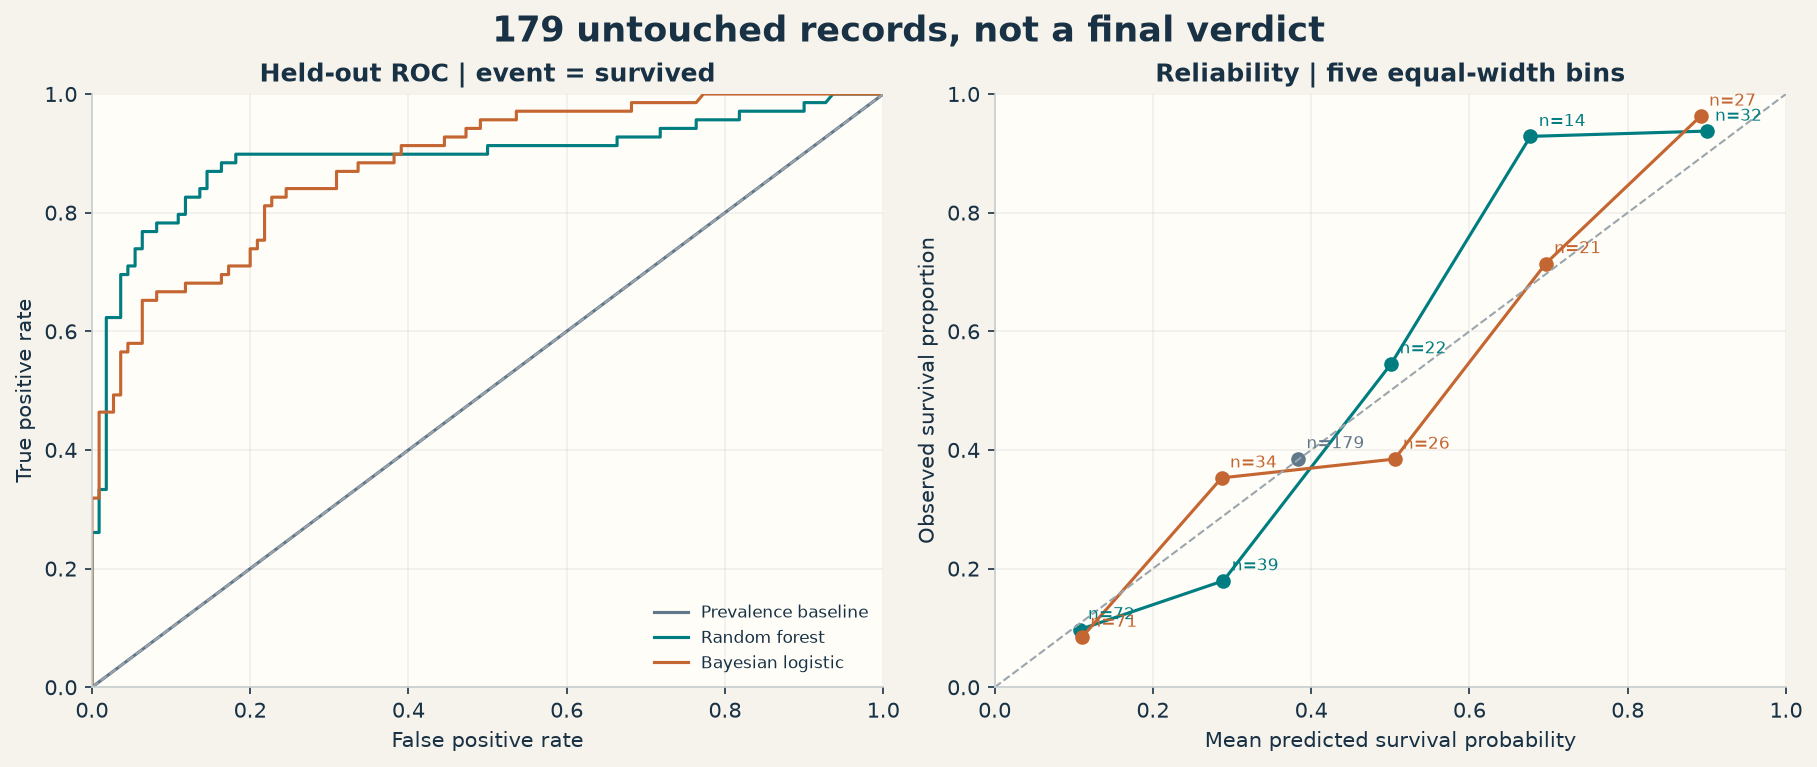

,bin,count,mean_probability,observed_rate,model
0,0,0,NaN,NaN,Prevalence baseline
1,1,179,0.383427,0.385475,Prevalence baseline
2,2,0,NaN,NaN,Prevalence baseline
3,3,0,NaN,NaN,Prevalence baseline
4,4,0,NaN,NaN,Prevalence baseline
5,0,72,0.107366,0.097222,Random forest
6,1,39,0.289054,0.179487,Random forest
7,2,22,0.501154,0.545455,Random forest
8,3,14,0.677041,0.928571,Random forest
9,4,32,0.899778,0.937500,Random forest


In [5]:
display(tables['metrics'].query("phase == 'cv'").groupby('model')[['roc_auc', 'brier', 'log_loss', 'balanced_accuracy']].agg(['mean', 'std']))
display(tables['metrics'].query("phase == 'test'"))
display(Image(filename=str(root / 'outputs' / 'python' / 'roc_calibration.png')))
display(tables['calibration'])

## 05 / Bayesian effects: uncertainty is part of the result

The inverse analytic negative-log-posterior Hessian provides the local Laplace covariance. Displayed intervals are **approximate marginal 95% credible intervals**, not exact intervals or MCMC output. Continuous effects are per one training sample SD (fare is log1p transformed). Reference levels are female, first class and embarkation at C. Odds ratios are not risk ratios. The coefficient intervals do not include model-selection or dataset-selection uncertainty.

,term,estimate,sd,lower,upper,odds_ratio,or_lower,or_upper,prior_sd
0,intercept,2.107384,0.391238,1.340572,2.874195,8.226689,3.821229,17.711163,5.0
1,age_z,-0.452163,0.112432,-0.672526,-0.231800,0.636250,0.510417,0.793105,2.5
2,log_fare_z,0.499191,0.185035,0.136530,0.861853,1.647389,1.146289,2.367543,2.5
3,family_size_z,-0.526978,0.144605,-0.810399,-0.243557,0.590387,0.444681,0.783835,2.5
4,age_missing,-0.184642,0.271661,-0.717088,0.347805,0.831402,0.488172,1.415956,2.5
5,sex_male,-2.608513,0.218868,-3.037486,-2.179540,0.073644,0.047955,0.113093,2.5
6,class_2,-0.625840,0.358990,-1.329447,0.077767,0.534812,0.264624,1.080870,2.5
7,class_3,-1.417552,0.385268,-2.172663,-0.662442,0.242306,0.113874,0.515591,2.5
8,embarked_Q,-0.041233,0.414627,-0.853887,0.771422,0.959606,0.425757,2.162839,2.5
9,embarked_S,-0.117497,0.266555,-0.639935,0.404941,0.889143,0.527327,1.499214,2.5


Posterior max absolute gradient: 6.47414066801133e-12
Optimizer: Optimization terminated successfully.


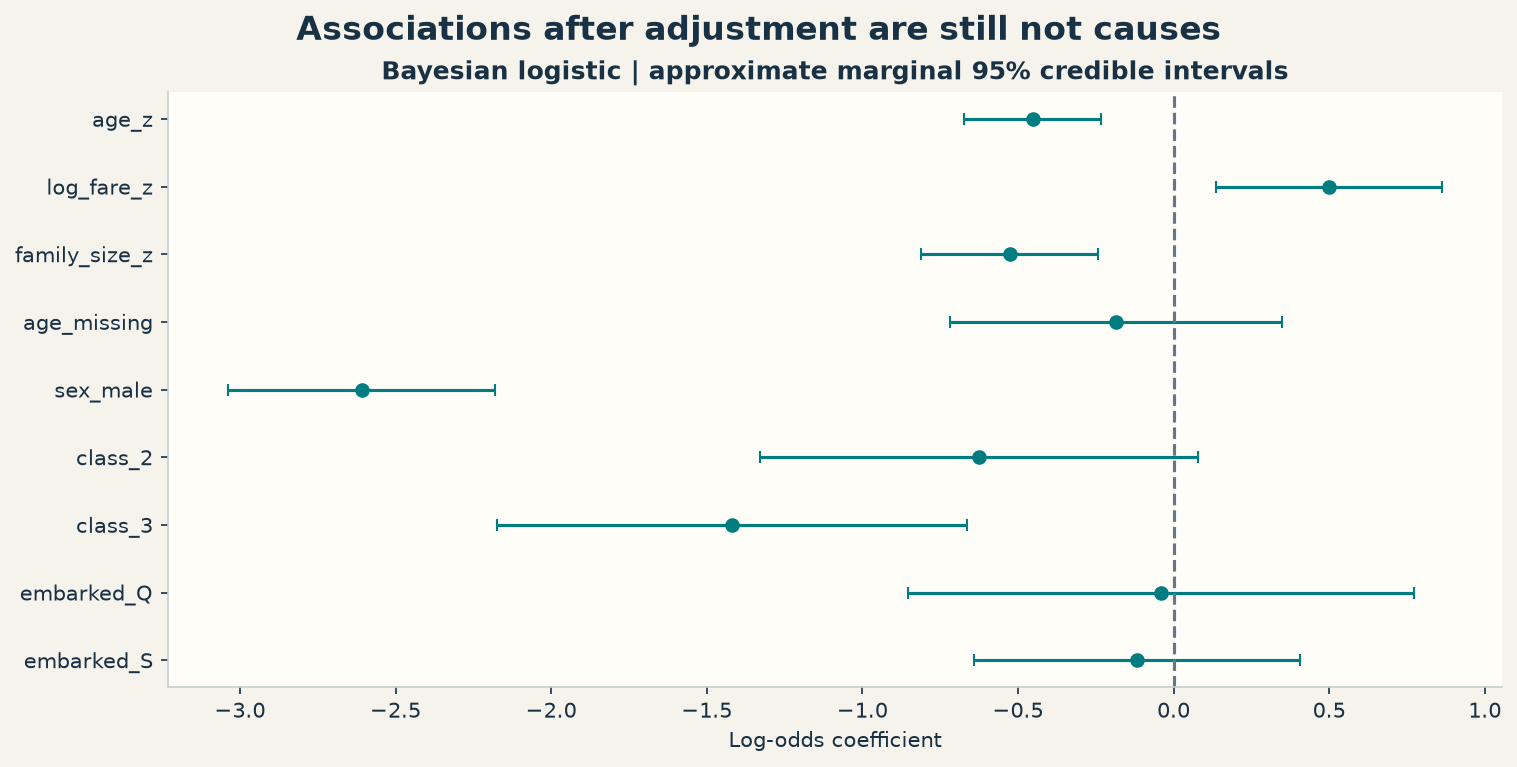

In [6]:
display(tables['coefficients'])
print('Posterior max absolute gradient:', summary['bayesian_max_abs_gradient'])
print('Optimizer:', summary['bayesian_optimizer_message'])
display(Image(filename=str(root / 'outputs' / 'python' / 'bayesian_effects.png')))

## 06 / A story with limits, not a leaderboard

The descriptive sex/class differences, rule associations and adjusted model coefficients answer different questions. They need not agree in magnitude. The small held-out sample and dependent historical records make score differences uncertain: no universal winner or statistically significant gain is claimed. Random-forest predictions may differ across R and Python, whereas the committed design matrices and Bayesian objective should match numerically.

**Fairness and selection:** historically recorded sex and class are not grounds for discriminatory decisions. Curated labeled records are not a random sample of a modern deployment population. Ticket groups imperfectly approximate family/social dependence. Unknown ages, incomplete records and correlated predictors limit generalization. These results cannot determine why an individual survived and must not support rescue recommendations.

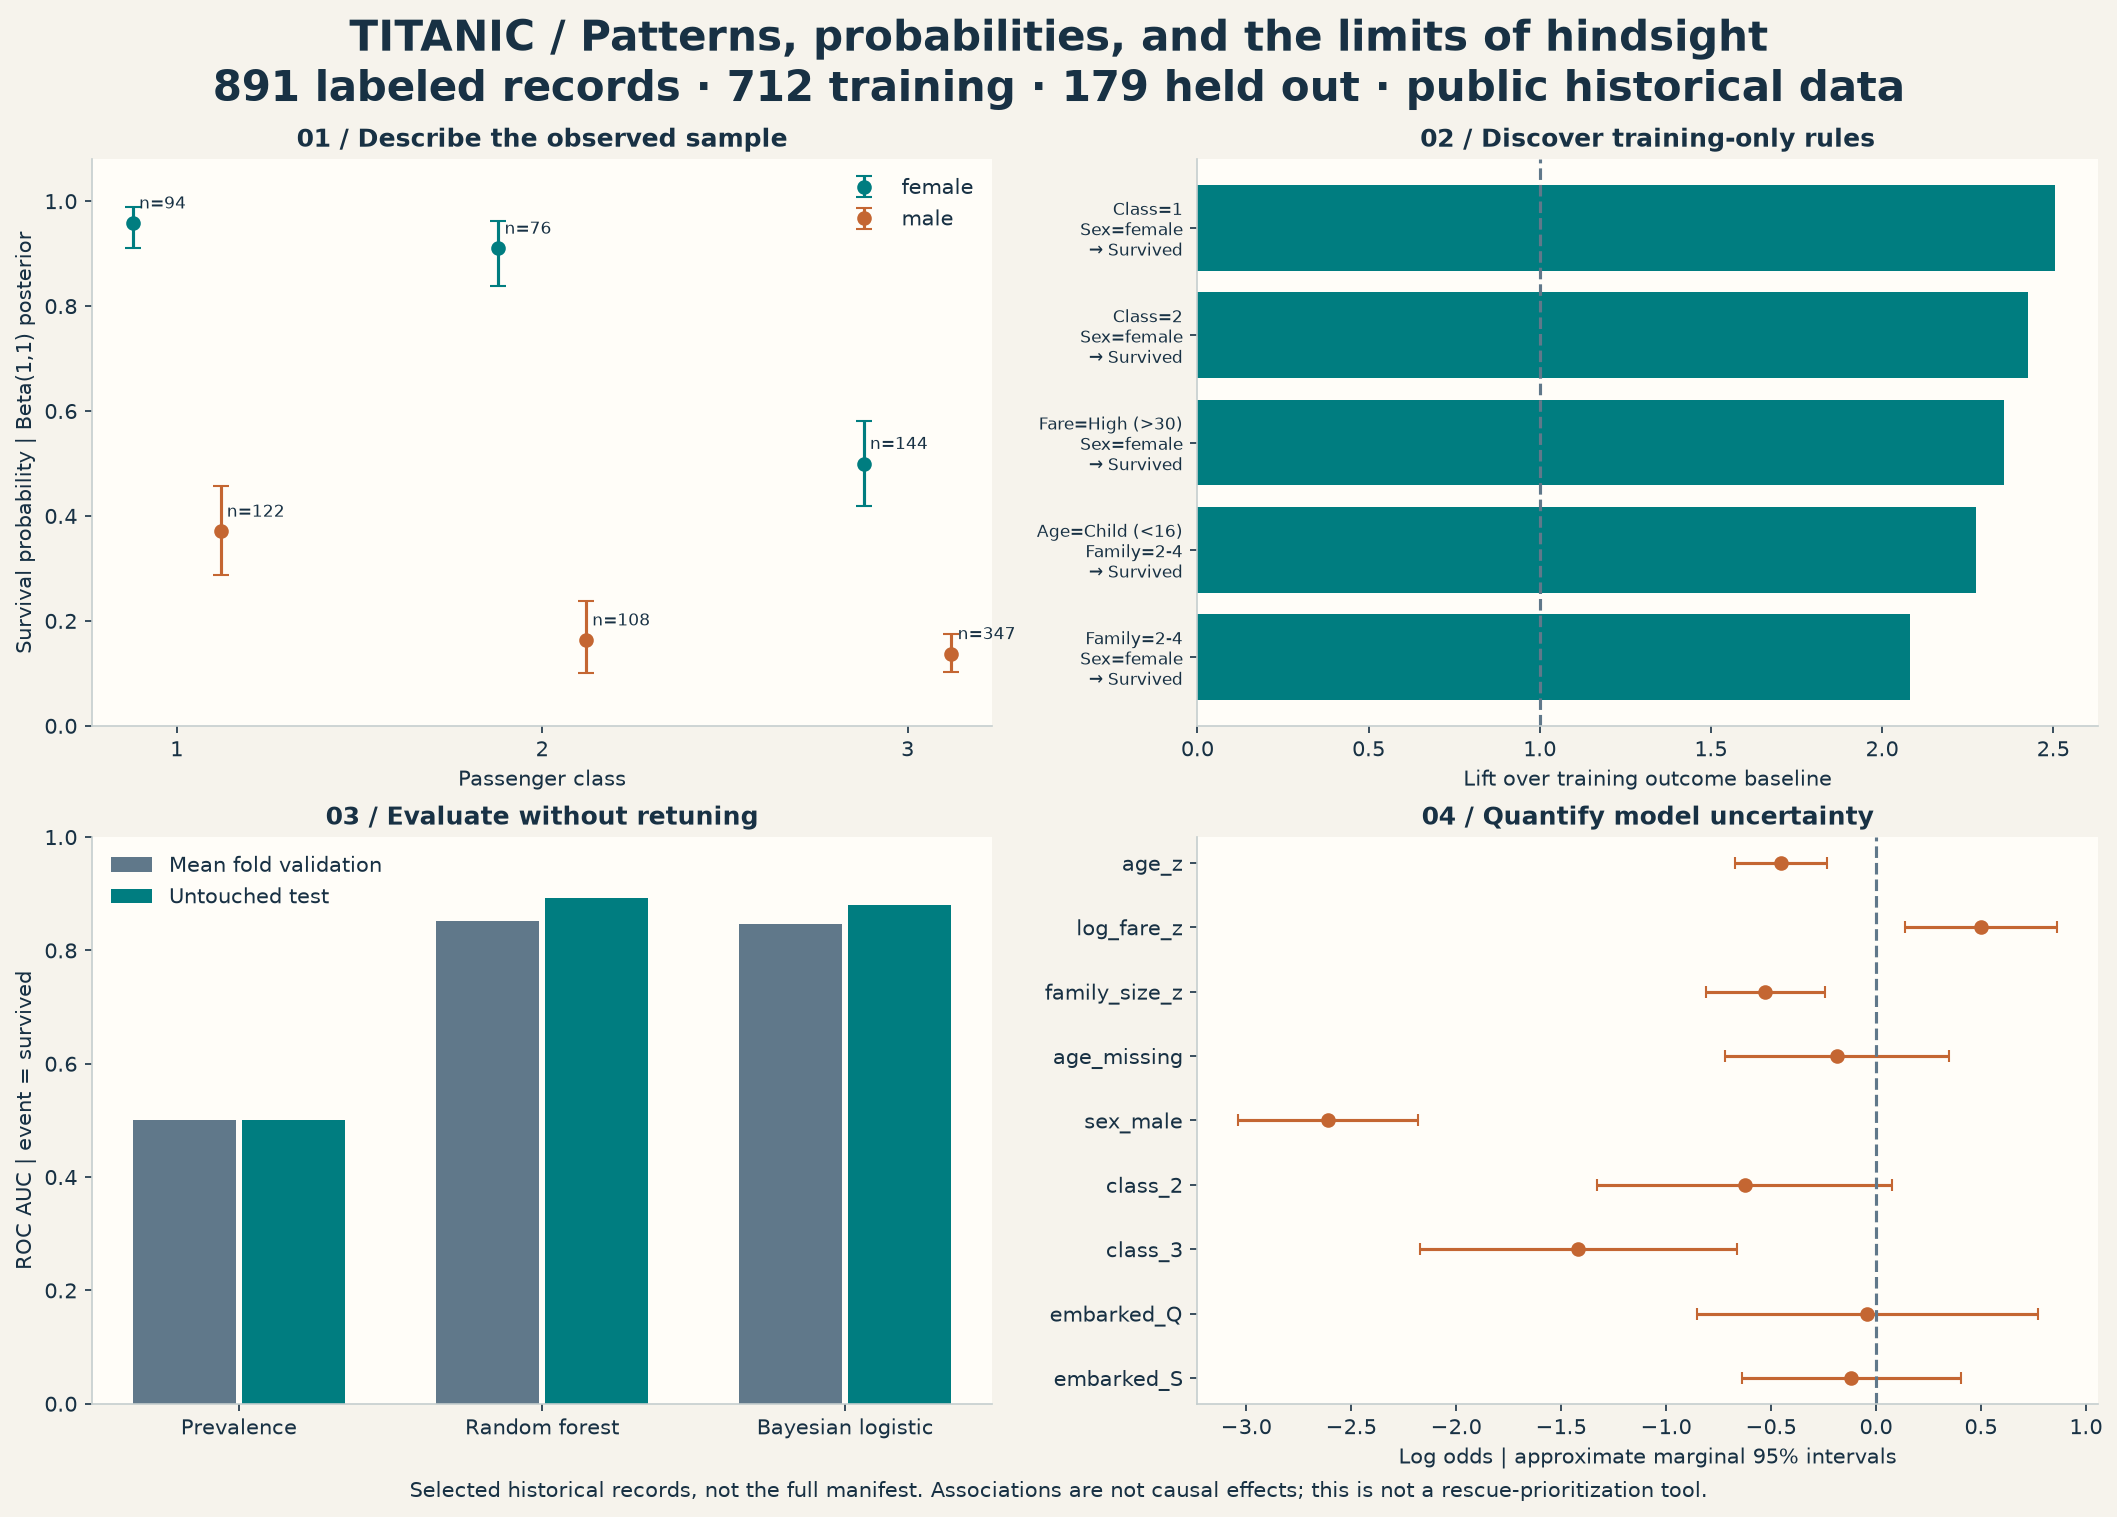

seed                                                                   20261014
n                                                                           891
train_n                                                                     712
test_n                                                                      179
survived                                                                    342
rule_count                                                                   46
bayesian_max_abs_gradient                                                   0.0
bayesian_optimizer_success                                                 True
bayesian_optimizer_message                Optimization terminated successfully.
prediction_type               Posterior-mode plug-in; Laplace marginal coeff...
coverage                      891 labeled records; not the complete Titanic ...
Name: Reproducibility summary, dtype: object

In [7]:
display(Image(filename=str(root / 'outputs' / 'python' / 'overview.png')))
display(pd.Series(summary, name='Reproducibility summary'))